# EDA: Data overview (Role A: Qi Heng)
Goal: understand the three datasets before modelling: class balance, text length,
token lengths for transformers, ISOT cleaning, and which words separate real vs fake.

## Setup

In [1]:
#Setup
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().parent))   # repo root, so `src` imports work

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.config import DATA_PROCESSED, FIGURES_DIR, LIAR_LABELS_6
from src.data.loaders import load_splits, load_isot_raw

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
DATASETS = ["isot", "liar", "covid"]
NICE = {"isot": "ISOT (articles)", "liar": "LIAR (claims)", "covid": "COVID (posts)"}

## Dataset sizes
**Takeaway:** ISOT has 38,226 articles after cleaning (split 80/10/10). LIAR and COVID use their official splits.
**In plain terms:** every team member trains and tests on exactly the same data, so our results are comparable.

In [2]:
#Load the datasets into one table
frames = []
for name in DATASETS:
    for split, df in load_splits(name).items():
        frames.append(df.assign(dataset=name, split=split))
data = pd.concat(frames, ignore_index=True)
data["n_words"] = data["text"].str.split().str.len()
print(data.groupby(["dataset", "split"]).size().unstack()[["train", "val", "test"]])

split    train   val  test
dataset                   
covid     6420  2140  2140
isot     30580  3823  3823
liar     10269  1284  1283


## Check: Reuters markers removed
**Takeaway:** 0 articles mention "Reuters" after cleaning.
**In plain terms:** almost every real ISOT article says "Reuters", so a model could cheat by spotting that one word.
We removed it so models have to learn from the actual content.

In [3]:
#Reuters verification cell
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import pandas as pd
from src.data.loaders import load_splits

isot = pd.concat(load_splits("isot").values())
print("Rows mentioning Reuters:", isot["text"].str.contains("reuters", case=False).sum())  # expect 0
for label in (0, 1):
    print(f"\n--- label {label} ---")
    for t in isot[isot.label == label].sample(5, random_state=1).text:
        print(t[:120])

Rows mentioning Reuters: 0

--- label 0 ---
The Moldovan government said on Thursday it has sent 57 servicemen to Ukraine to participate in military exercises start
A coalition of U.S. cities, companies and other groups said on Thursday that many in the United States remained committe
Russia did not place adverts on Facebook Inc to try to influence the 2016 U.S. Presidential election, Kremlin spokesman 
Republican presidential nominee Donald Trump will lay out on Saturday what he would do in the first 100 days of his admi
Zimbabwe opposition leader Morgan Tsvangirai said he was baffled by President Robert Mugabe s address to the nation on S

--- label 1 ---
Donald Trump has been throwing around the false claim that former Director of National Intelligence James Clapper said t
A Hollywood actor defending the 2nd Amendment is a pretty rare occurrence. Kudos to Kurt Russell for sticking to your gu
Don t think for a minute this union-style Black Lives Matter/Occupy type sit-in wasn t orche

## 1. Class balance
**Takeaway:** All three datasets are close to 50/50 (ISOT 45%, LIAR 44%, COVID 48% fake), but not exactly.
**In plain terms:** if a dataset has more real than fake articles, a model can look good just by guessing "real" often.
Macro-F1 scores both classes equally, so it's our main metric instead of accuracy.

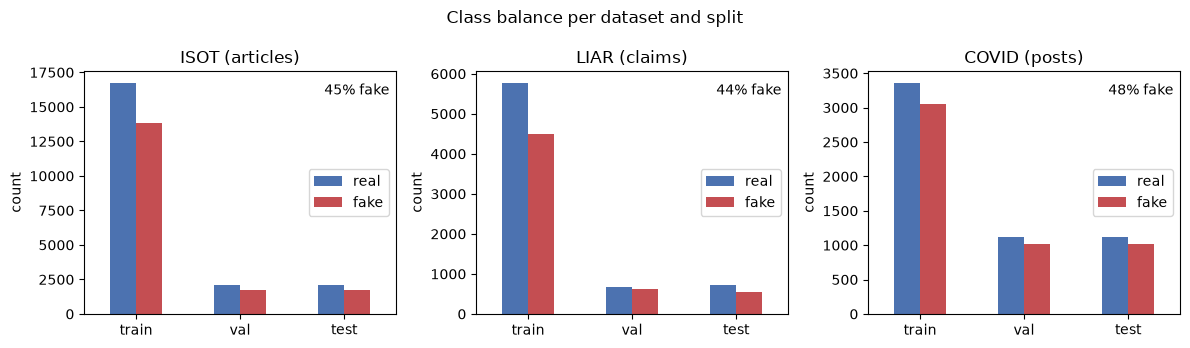

In [4]:
#Plot 1, class balance

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=False)
for ax, name in zip(axes, DATASETS):
    counts = (data[data.dataset == name]
              .groupby(["split", "label"]).size().unstack()
              .reindex(["train", "val", "test"]))
    counts.columns = ["real", "fake"]
    counts.plot.bar(ax=ax, color=["#4C72B0", "#C44E52"], rot=0)
    ax.set_title(NICE[name]); ax.set_xlabel(""); ax.set_ylabel("count")
    pct_fake = counts["fake"].sum() / counts.values.sum()
    ax.text(0.98, 0.95, f"{pct_fake:.0%} fake", transform=ax.transAxes, ha="right", va="top")
fig.suptitle("Class balance per dataset and split")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "eda_class_balance.png", dpi=150)

## 1b. LIAR 6-class labels
**Takeaway:** LIAR rates each claim on 6 levels, from "pants-fire" (most false) to "true".
"Pants-fire" is the rarest (1,050); the others have 2,063–2,638 each.
**In plain terms:** for the real/fake task we group the 3 red levels as fake and the 3 blue levels as real.
The 6-level task is much harder because neighbouring levels (e.g. "half-true" vs "mostly-true") are very similar.

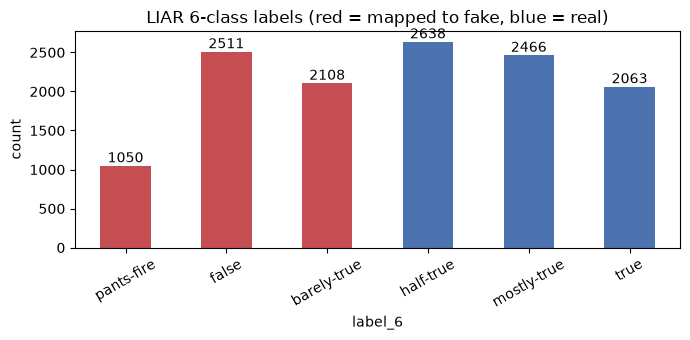

In [5]:
#Plot 1b, LIAR 6-class distribution

liar = data[data.dataset == "liar"]
counts6 = liar["label_6"].value_counts().reindex(LIAR_LABELS_6)
colors = ["#C44E52"] * 3 + ["#4C72B0"] * 3          # red = mapped to fake, blue = real
ax = counts6.plot.bar(color=colors, rot=30, figsize=(7, 3.5))
ax.set_title("LIAR 6-class labels (red = mapped to fake, blue = real)")
ax.set_ylabel("count"); ax.bar_label(ax.containers[0])
plt.tight_layout(); plt.savefig(FIGURES_DIR / "eda_liar_6class.png", dpi=150)

## 2. Text length
**Takeaway:** ISOT articles are ~360 words, LIAR claims ~17, COVID posts ~17–32.
On COVID, real posts are almost twice as long as fake ones (32 vs 17 words); on LIAR there's no difference.
**In plain terms:** the three datasets are genuinely different formats, which is the point of our comparison.
On COVID, a model could partly guess the label just from how long a post is.

                mean    50%    95%     max
dataset label                             
covid   0       32.0   32.0   48.0  1484.0
        1       22.0   17.0   45.0  1456.0
isot    0      381.0  356.0  888.0  5145.0
        1      429.0  378.0  855.0  8134.0
liar    0       18.0   17.0   33.0    66.0
        1       17.0   16.0   32.0    60.0


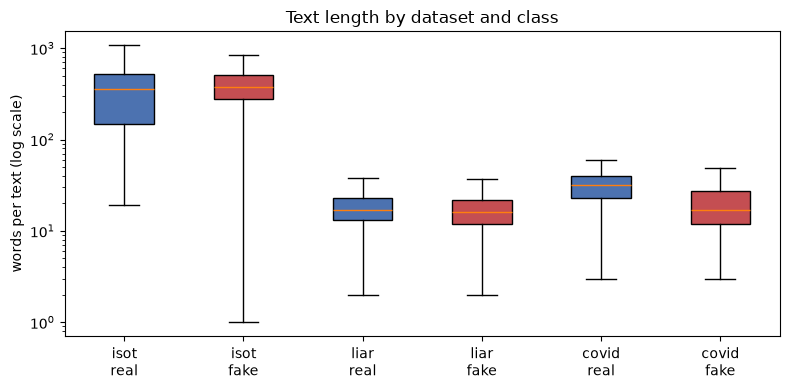

In [6]:
#Plot 2, text length

summary = (data.groupby(["dataset", "label"])["n_words"]
           .describe(percentiles=[0.5, 0.95])[["mean", "50%", "95%", "max"]]
           .round(0))
print(summary)
summary.to_csv(FIGURES_DIR / "eda_length_summary.csv")

fig, ax = plt.subplots(figsize=(8, 4))
groups, ticks = [], []
for name in DATASETS:
    for label, lab_name in [(0, "real"), (1, "fake")]:
        groups.append(data[(data.dataset == name) & (data.label == label)]["n_words"].clip(lower=1))
        ticks.append(f"{name}\n{lab_name}")
bp = ax.boxplot(groups, showfliers=False, patch_artist=True)
for patch, color in zip(bp["boxes"], ["#4C72B0", "#C44E52"] * 3):
    patch.set_facecolor(color)
ax.set_xticks(range(1, len(ticks) + 1), ticks)
ax.set_yscale("log"); ax.set_ylabel("words per text (log scale)")
ax.set_title("Text length by dataset and class")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "eda_length_by_dataset.png", dpi=150)

## 3. Token lengths (for transformers)
**Takeaway:** Suggested limits: LIAR 64 tokens, COVID 128, ISOT 512. Even at 512, 40% of ISOT articles get cut off.
**In plain terms:** BERT-style models can only read a fixed number of tokens (roughly words) per text.
Short texts fit easily, but many long ISOT articles get cut off, so the model doesn't see the full article.

In [7]:
#Token lengths for transformers (for Menujaa and Arshad)

try:
    from transformers import AutoTokenizer
    tok = AutoTokenizer.from_pretrained("bert-base-uncased")
    def n_tokens(texts):
        return np.array([len(ids) for ids in tok(list(texts), add_special_tokens=True)["input_ids"]])
    method = "BERT tokenizer"
except Exception as err:                      # offline fallback: ~1.3 WordPiece tokens per word
    print("Tokenizer unavailable, estimating from word counts:", err)
    def n_tokens(texts):
        return (pd.Series(texts).str.split().str.len() * 1.3).to_numpy()
    method = "estimate (1.3 tokens/word)"

rows = []
for name in DATASETS:
    texts = data[data.dataset == name]["text"]
    sample = texts.sample(min(2000, len(texts)), random_state=42)
    t = n_tokens(sample)
    rows.append({"dataset": name, "median_tokens": int(np.median(t)),
                 "p95_tokens": int(np.percentile(t, 95)),
                 **{f"% > {k}": round(100 * (t > k).mean(), 1) for k in (64, 128, 256, 512)}})
trunc = pd.DataFrame(rows).set_index("dataset")
print(f"Token lengths ({method}, sample of up to 2,000 per dataset):")
print(trunc)
trunc.to_csv(FIGURES_DIR / "eda_token_lengths.csv")

c:\dev\NLP-Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1227 > 512). Running this sequence through the model will result in indexing errors


Token lengths (BERT tokenizer, sample of up to 2,000 per dataset):
         median_tokens  p95_tokens  % > 64  % > 128  % > 256  % > 512
dataset                                                              
isot               465        1099    97.0     87.5     77.0     40.0
liar                22          41     0.2      0.0      0.0      0.0
covid               47          93    29.4      0.2      0.0      0.0


## 4. ISOT cleaning
**Takeaway:** 44,898 → 38,226 articles. We removed 839 near-empty articles and 5,833 duplicates; 93% of the removed rows were fake.
Leakage check (simple model, macro-F1): subject column only = 1.000 · raw text = 0.992 · cleaned = **0.980**.
**In plain terms:** the raw data gives the answer away. A model using only the topic label, without reading any text,
scores perfectly, and duplicate articles appear in both training and test data. Cleaning gives an honest score.

         raw  clean  removed
label                       
real   21417  20921      496
fake   23481  17305     6176


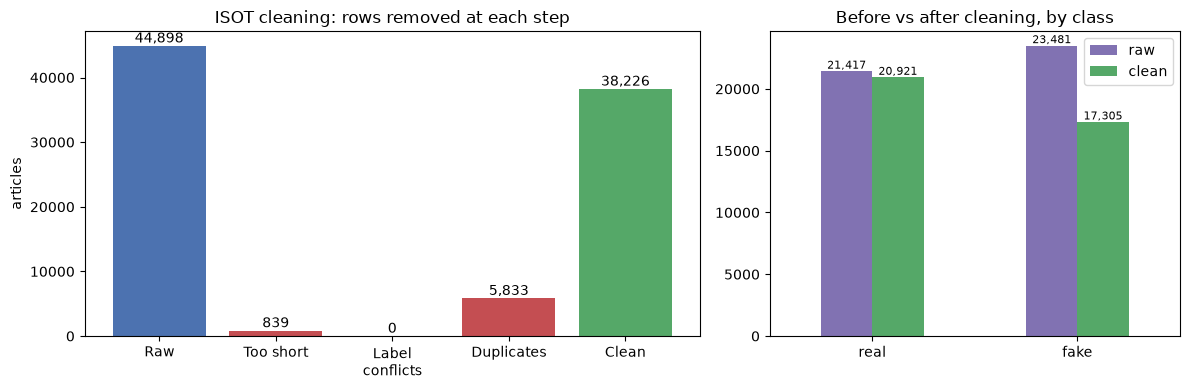

In [8]:
#Plot 3, ISOT cleaning (for leakage slide)

r = json.loads((DATA_PROCESSED / "isot" / "report.json").read_text())
steps = ["rows_raw", "dropped_short", "dropped_label_conflicts", "dropped_duplicates", "rows_clean"]
labels = ["Raw", "Too short", "Label\nconflicts", "Duplicates", "Clean"]
vals = [r[s] for s in steps]

raw_counts = load_isot_raw()["label"].value_counts().sort_index()
clean_counts = data[data.dataset == "isot"]["label"].value_counts().sort_index()
before_after = pd.DataFrame({"raw": raw_counts, "clean": clean_counts}).rename(index={0: "real", 1: "fake"})
before_after["removed"] = before_after["raw"] - before_after["clean"]
print(before_after)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [3, 2]})
bars = ax1.bar(labels, vals, color=["#4C72B0", "#C44E52", "#C44E52", "#C44E52", "#55A868"])
ax1.bar_label(bars, labels=[f"{v:,}" for v in vals])
ax1.set_ylabel("articles"); ax1.set_title("ISOT cleaning: rows removed at each step")
before_after[["raw", "clean"]].plot.bar(ax=ax2, rot=0, color=["#8172B2", "#55A868"])
ax2.set_title("Before vs after cleaning, by class"); ax2.set_xlabel("")
for c in ax2.containers:
    ax2.bar_label(c, labels=[f"{int(v):,}" for v in c.datavalues], fontsize=8)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "isot_cleaning.png", dpi=150)

## 5. Words that separate real vs fake
**Takeaway:**
- ISOT: real = world news topics (Myanmar, Catalonia); fake = web clutter (photo credits, Twitter links, page code)
- COVID: many real posts are Nigerian case-count updates (Lagos, Ogun, Kano)
- LIAR: mostly people's names, with no strong pattern

**In plain terms:** on ISOT and COVID, a model can tell real from fake by *where* the text came from or *what topic* it covers,
without checking whether it's true. LIAR doesn't have these shortcuts, which helps explain why it's the hardest dataset.

In [9]:
#Words most linked to each class

from sklearn.feature_extraction.text import CountVectorizer

def top_words(name, k=12):
    df = data[(data.dataset == name) & (data.split == "train")]
    vec = CountVectorizer(stop_words="english", min_df=5, token_pattern=r"(?u)\b[a-zA-Z]{3,}\b")
    X = vec.fit_transform(df["text"])
    vocab = np.array(vec.get_feature_names_out())
    fake = np.asarray(X[(df["label"] == 1).to_numpy()].sum(0)).ravel() + 1   # +1 smoothing
    real = np.asarray(X[(df["label"] == 0).to_numpy()].sum(0)).ravel() + 1
    log_odds = np.log(fake / fake.sum()) - np.log(real / real.sum())
    order = np.argsort(log_odds)
    return pd.DataFrame({f"{name}: real": vocab[order[:k]], f"{name}: fake": vocab[order[::-1][:k]]})

top = pd.concat([top_words(n) for n in DATASETS], axis=1)
print(top.to_string(index=False))
top.to_csv(FIGURES_DIR / "eda_top_words.csv", index=False)

isot: real   isot: fake    liar: real  liar: fake  covid: real      covid: fake
  rohingya        https     accidents    deciding        lagos           donald
   rakhine          pic        remain  socialists          fct            gates
   myanmar        getty incarceration       terry         ogun            claim
      zuma       flickr        obtain     cabinet          oyo      donaldtrump
puigdemont          fjs      expenses       betty indiawillwin        president
       fdp  somodevilla         seats proposition          edo             cure
       suu          acr           bar  corruption       kaduna coronavirusfacts
       kyi   screenshot      huckabee        sean     drtedros            photo
   catalan        cdata       decades         jan       bauchi            trump
    kirkuk      angerer      december     options      plateau            image
 mnangagwa filessupport          soon      sutton         kano   misinformation
     rajoy      mcnamee      generate   

## Summary
1. **Three different formats:** long articles, short claims and social posts, all roughly balanced, so we use macro-F1.
2. **Raw ISOT cheats:** it contains clues that give away the answer. After cleaning, the honest baseline is 0.980 (down from 0.992).
3. **Easy ≠ smart:** ISOT and COVID score high partly because of topic, source and formatting clues, not because models understand truth.
   LIAR has none of these clues, so it is the real test.